# News Topic Discovery Using K-Means Clustering 

**Goal:** group unlabeled news articles into topics using only their text.

**Project line:** Load → Clean → Split → TF-IDF → SVD (LSA) + Normalize → choose settings → K-Means → Evaluate → Interpret clusters → Naive Bayes on clusters → Summary

Original category labels are **never used to train** K-Means. They are used only to *evaluate* and to choose settings.

## Step 1: Import libraries

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score, accuracy_score,
                             classification_report, confusion_matrix)

sns.set_style("whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2: Load the dataset and look at it
Headers, footers and quoted replies are removed so the model learns from the article text, not from e-mail metadata.

Total articles: 18846
Original categories: 20
Empty articles: 515
Duplicate articles: 559


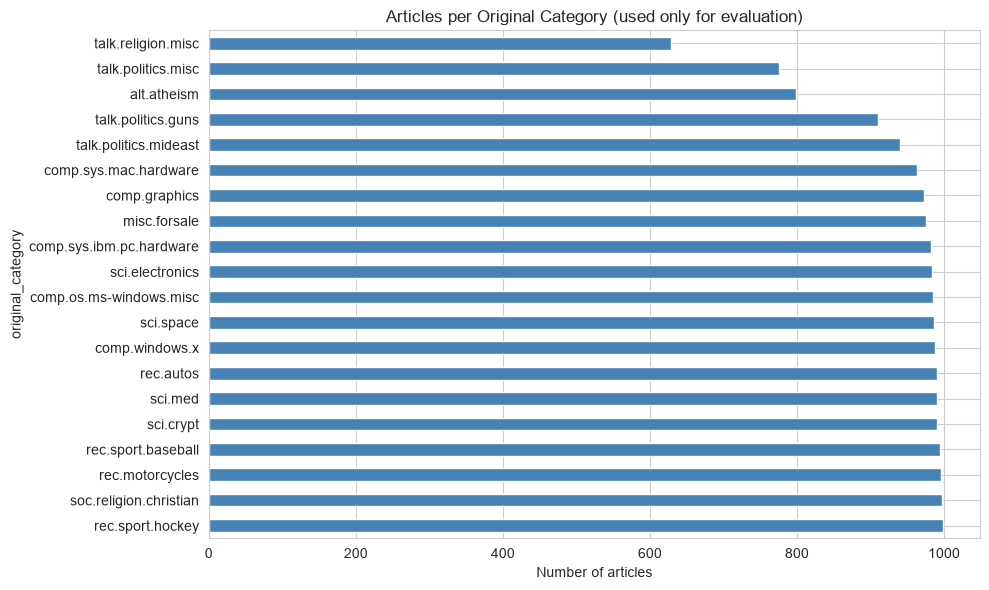

In [3]:
newsgroups = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes"))

df = pd.DataFrame({
    "article": newsgroups.data,
    "original_label": newsgroups.target
})
df["original_category"] = df["original_label"].map(lambda i: newsgroups.target_names[i])

print("Total articles:", len(df))
print("Original categories:", len(newsgroups.target_names))
print("Empty articles:", df["article"].str.strip().eq("").sum())
print("Duplicate articles:", df["article"].duplicated().sum())

plt.figure(figsize=(10, 6))
df["original_category"].value_counts().plot(kind="barh", color="steelblue")
plt.title("Articles per Original Category (used only for evaluation)")
plt.xlabel("Number of articles")
plt.tight_layout()
plt.show()

## Step 3: Clean the text
- lowercase, remove e-mail addresses and links
- keep only letters (removes numbers and symbols)
- remove empty articles, duplicates and very short articles (fewer than 10 words), because they carry no topic information

In [4]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"\S+@\S+", " ", text)          # e-mail addresses
    text = re.sub(r"http\S+|www\S+", " ", text)   # links
    text = re.sub(r"[^a-z\s]", " ", text)          # keep letters only
    return re.sub(r"\s+", " ", text).strip()

df["clean_text"] = df["article"].apply(clean_text)

before = len(df)
df = df[df["clean_text"].str.split().str.len() >= 10]
df = df.drop_duplicates(subset="clean_text").reset_index(drop=True)
print(f"Articles before cleaning: {before}")
print(f"Articles after cleaning : {len(df)}")

Articles before cleaning: 18846
Articles after cleaning : 17705


## Step 4: Split into training and testing sets
K-Means learns from the training set. The test set checks that the clusters also work on unseen articles.

In [5]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training articles:", len(train_df))
print("Testing articles :", len(test_df))

Training articles: 14164
Testing articles : 3541


## Step 5: Convert text to numbers (TF-IDF)
TF-IDF gives a high weight to words that are frequent in an article but rare in the rest of the dataset.
`sublinear_tf` dampens very long articles; `ngram_range=(1, 2)` also captures two-word phrases such as *hard drive*.

In [6]:
tfidf = TfidfVectorizer(
    stop_words="english",
    sublinear_tf=True,
    ngram_range=(1, 2),
    max_df=0.5,
    min_df=5,
    max_features=20000
)

X_train_tfidf = tfidf.fit_transform(train_df["clean_text"])
X_test_tfidf = tfidf.transform(test_df["clean_text"])

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix :", X_test_tfidf.shape)

Training matrix: (14164, 20000)
Testing matrix : (3541, 20000)


## Step 6: Reduce dimensions (SVD / LSA) and normalize
SVD compresses 20,000 sparse features into a few hundred dense "topic-like" dimensions.
**Normalizing** each article vector to length 1 makes K-Means compare the *direction* (topic) of articles instead of their length, which is the key fix for text clustering.

We fit 300 components once and test smaller sizes by using only the first 100 or 200 of them.

Variance explained by 300 components: 0.1999


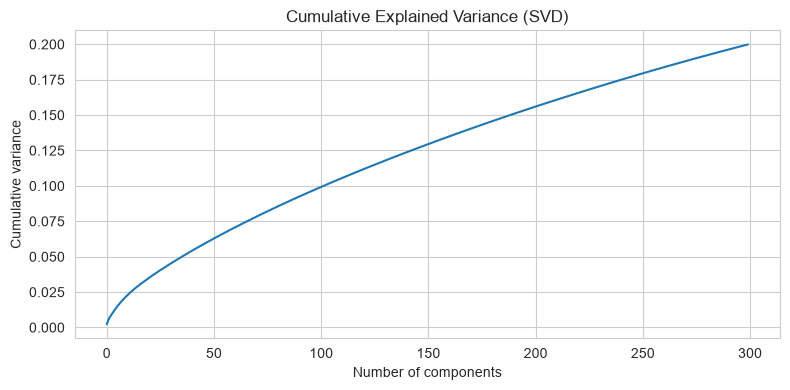

In [7]:
svd = TruncatedSVD(n_components=300, random_state=42)
X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

print("Variance explained by 300 components:", round(svd.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(svd.explained_variance_ratio_))
plt.title("Cumulative Explained Variance (SVD)")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance")
plt.tight_layout()
plt.show()

## Step 7: Choose the best settings
We try different numbers of SVD dimensions and clusters (k) and compare them.

- **Silhouette**: how well separated the clusters are (no labels needed)
- **ARI** and **NMI**: agreement with the original categories (higher is better; labels are used only to *measure*)

Silhouette stays low for text data even with good clusters, so ARI/NMI are the main guide. The best setting is chosen by the average of ARI and NMI.

In [8]:
y_train = train_df["original_label"].values
results = []

for dims in [100, 200, 300]:
    Xd = normalize(X_train_svd[:, :dims])
    for k in [10, 15, 20, 25, 30]:
        km = KMeans(n_clusters=k, random_state=42, n_init=5).fit(Xd)
        labels = km.labels_
        results.append({
            "SVD dims": dims,
            "k": k,
            "Silhouette": silhouette_score(Xd, labels, sample_size=3000, random_state=42),
            "ARI": adjusted_rand_score(y_train, labels),
            "NMI": normalized_mutual_info_score(y_train, labels),
        })

results_df = pd.DataFrame(results)
results_df["Score"] = (results_df["ARI"] + results_df["NMI"]) / 2
results_df = results_df.sort_values("Score", ascending=False).reset_index(drop=True)
display(results_df.round(4))

best = results_df.iloc[0]
BEST_DIMS, BEST_K = int(best["SVD dims"]), int(best["k"])
print(f"\nBest settings -> SVD dims: {BEST_DIMS}, clusters (k): {BEST_K}")

,SVD dims,k,Silhouette,ARI,NMI,Score
0,100,20,0.0579,0.2349,0.4625,0.3487
1,100,30,0.0673,0.2521,0.4307,0.3414
2,100,15,0.0548,0.2191,0.4507,0.3349
3,100,25,0.0640,0.2384,0.4205,0.3294
4,300,25,0.0267,0.2020,0.4448,0.3234
5,100,10,0.0451,0.2109,0.4332,0.3221
6,200,25,0.0372,0.1962,0.4371,0.3167
7,200,30,0.0395,0.1859,0.4399,0.3129
8,200,20,0.0372,0.1924,0.4271,0.3098
9,300,15,0.0209,0.1657,0.4445,0.3051



Best settings -> SVD dims: 100, clusters (k): 20


## Step 8: Train the final K-Means model
With the best settings, more random restarts (`n_init=20`) for a stable result.

In [9]:
X_train = normalize(X_train_svd[:, :BEST_DIMS])
X_test = normalize(X_test_svd[:, :BEST_DIMS])

kmeans = KMeans(n_clusters=BEST_K, random_state=42, n_init=20)
kmeans.fit(X_train)

train_clusters = kmeans.labels_
test_clusters = kmeans.predict(X_test)      # assign unseen articles to learned clusters

print("K-Means trained with", BEST_K, "clusters")
print("Test predictions (first 20):", test_clusters[:20])

K-Means trained with 20 clusters
Test predictions (first 20): [ 9  9 15  9  9  1 13  5 16  4  4 19 11 16 12 10  6 12 18  9]


## Step 9: Evaluate the final model

In [10]:
y_test = test_df["original_label"].values

def evaluate(X, clusters, y):
    return {
        "Silhouette": silhouette_score(X, clusters, sample_size=min(3000, len(X)), random_state=42),
        "ARI": adjusted_rand_score(y, clusters),
        "NMI": normalized_mutual_info_score(y, clusters),
    }

final = pd.DataFrame({
    "Version 1 (baseline, test)": {"Silhouette": 0.0469, "ARI": 0.0657, "NMI": np.nan},
    "(train)": evaluate(X_train, train_clusters, y_train),
    "(test)": evaluate(X_test, test_clusters, y_test),
}).round(4)
display(final)

,"Version 1 (baseline, test)",(train),(test)
Silhouette,0.0469,0.0579,0.0569
ARI,0.0657,0.2349,0.2263
NMI,NaN,0.4625,0.4555


**How to read this:** ARI/NMI close to 0 mean the clusters look random compared with the real categories; higher means better agreement. The baseline silhouette was measured in a different (un-normalized) space, so compare ARI/NMI first.
Similar *train* and *test* scores mean the model generalizes to unseen articles.

## Step 10: Cluster sizes

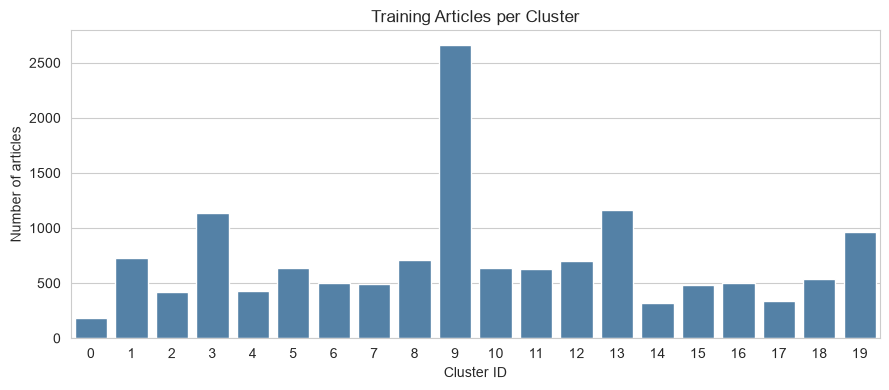

In [11]:
sizes = pd.Series(train_clusters).value_counts().sort_index()

plt.figure(figsize=(9, 4))
sns.barplot(x=sizes.index, y=sizes.values, color="steelblue")
plt.title("Training Articles per Cluster")
plt.xlabel("Cluster ID")
plt.ylabel("Number of articles")
plt.tight_layout()
plt.show()

## Step 11: Interpret the clusters
For every cluster we show:
1. its **top words** (the topic keywords),
2. the **most common original category** inside it, and the **purity** (share of articles from that category).
This is how we give each cluster a human-readable topic name.

In [12]:
terms = tfidf.get_feature_names_out()
centers_tfidf = kmeans.cluster_centers_ @ svd.components_[:BEST_DIMS]

# which original category dominates each cluster
crosstab = pd.crosstab(train_clusters, train_df["original_category"])
dominant = crosstab.idxmax(axis=1)
purity = (crosstab.max(axis=1) / crosstab.sum(axis=1)).round(2)

rows = []
for c in range(BEST_K):
    top = [terms[i] for i in centers_tfidf[c].argsort()[-8:][::-1]]
    rows.append({"Cluster": c, "Size": int(sizes[c]), "Top words": ", ".join(top),
                 "Main original category": dominant[c], "Purity": purity[c]})

cluster_table = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80)
display(cluster_table)

,Cluster,Size,Top words,Main original category,Purity
0,0,182,"armenian, armenians, turkish, genocide, armenia, muslim, government, turks",talk.politics.mideast,0.97
1,1,729,"god, jesus, christ, bible, christian, believe, sin, christians",soc.religion.christian,0.63
2,2,420,"drive, hard, scsi, disk, drives, hard drive, controller, ide",comp.sys.ibm.pc.hardware,0.43
3,3,1133,"people, think, don, say, point, just, believe, true",alt.atheism,0.26
4,4,430,"key, chip, clipper, encryption, keys, government, clipper chip, escrow",sci.crypt,0.95
5,5,634,"game, team, hockey, games, play, espn, nhl, season",rec.sport.hockey,0.92
6,6,499,"cause, probably, medical, doctor, disease, msg, day, food",sci.med,0.84
7,7,495,"space, orbit, earth, nasa, shuttle, launch, moon, cost",sci.space,0.88
8,8,707,"gun, law, government, people, guns, state, don, right",talk.politics.guns,0.40
9,9,2660,"just, like, don, know, bike, ve, think, good",rec.motorcycles,0.20


### Cluster vs. original category heatmap
Each row is a cluster. A bright cell means most articles of that cluster come from one category.

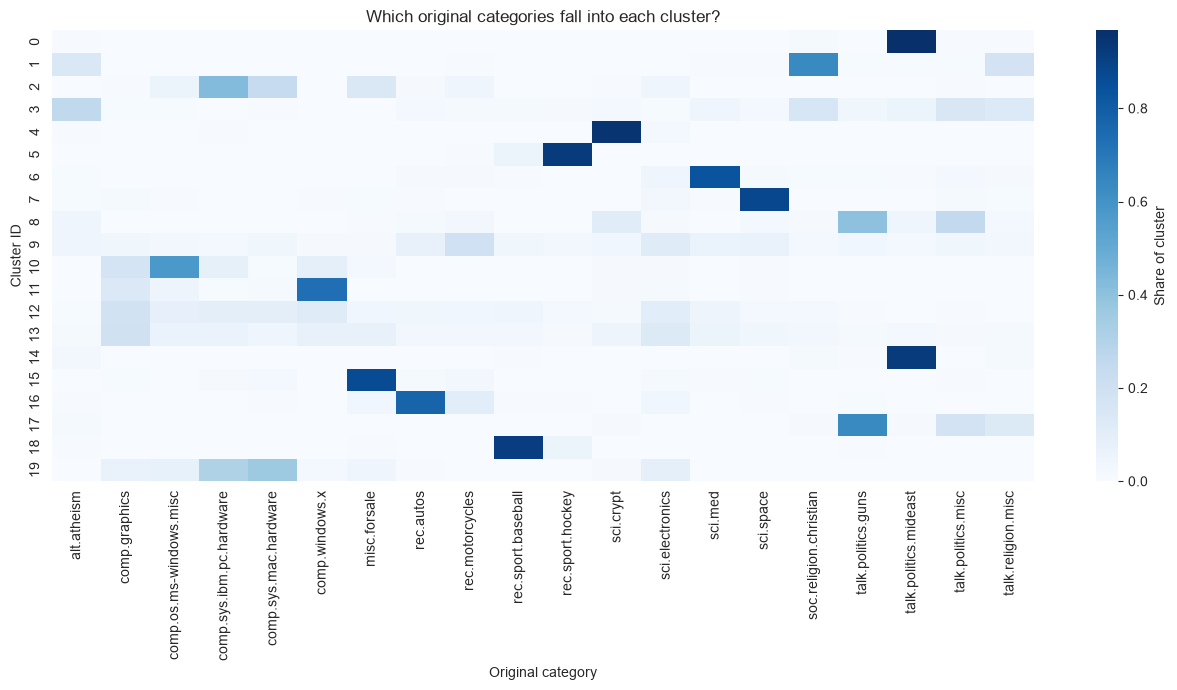

In [13]:
share = crosstab.div(crosstab.sum(axis=1), axis=0)

plt.figure(figsize=(13, 7))
sns.heatmap(share, cmap="Blues", cbar_kws={"label": "Share of cluster"})
plt.title("Which original categories fall into each cluster?")
plt.xlabel("Original category")
plt.ylabel("Cluster ID")
plt.tight_layout()
plt.show()

### Sample articles
Reading real articles confirms that the top words describe the cluster.

In [14]:
for c in [0, 1, 2]:
    print("=" * 70)
    print(f"CLUSTER {c}  |  keywords: {cluster_table.loc[c, 'Top words']}")
    print("=" * 70)
    for text in train_df.loc[train_clusters == c, "article"].head(2):
        print(text.strip()[:400].replace("\n", " "))
        print("-" * 50)

CLUSTER 0  |  keywords: armenian, armenians, turkish, genocide, armenia, muslim, government, turks
Very sensible.     Must you rave so? Fascist x-Soviet Armenian Government engaged in  disgusting cowardly massacres of Azeri women and children. I am really sorry if that fact bothers you.    More ridicule, I take it? Still not addressing the original points made.   Then what seems to be the problem? Did you ever read newspaper at all?   "PAINFUL SEARCH .."  THE GRUESOME extent of February's killi
--------------------------------------------------
there you go the greeks have been trying for over a year, even though mr. mitsotakis was threatening the EC that if Macedonia was recognized that the honourable papandreou would be back...   well i guess the europeans pulled the plug eh ..? theis is just one other example about the corruptness and the "perversity" of greek foreign policy objectives...  pity to those who have to live under the gree
------------------------------------------------

## Step 12: Visualize the clusters in 2D
PCA squeezes the data into two dimensions only for plotting. Some overlap is expected because news topics share vocabulary.

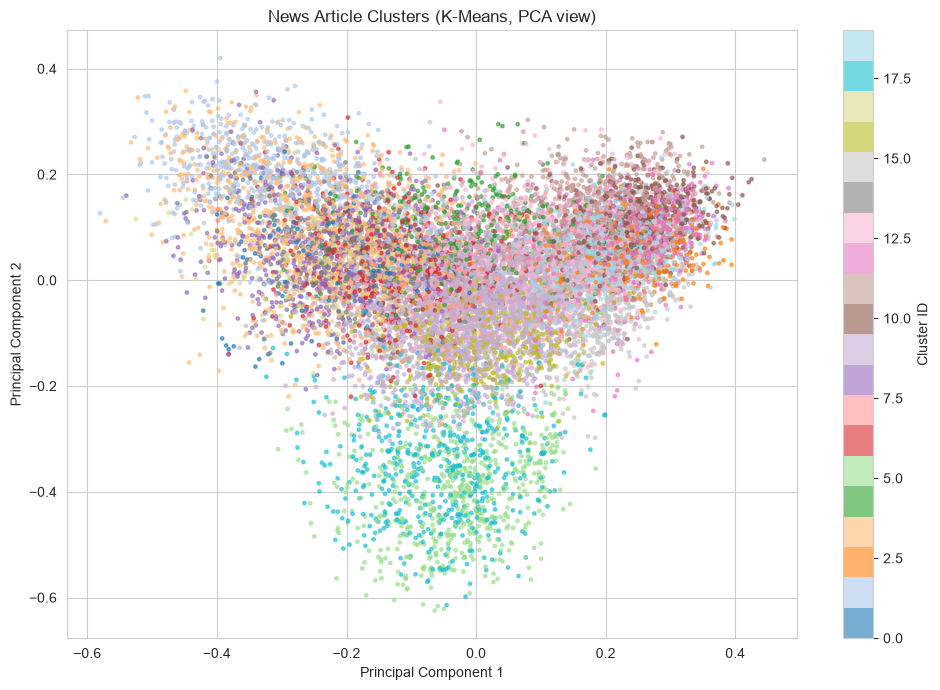

In [15]:
X_2d = PCA(n_components=2, random_state=42).fit_transform(X_train)

plt.figure(figsize=(10, 7))
sc = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=train_clusters, cmap="tab20", s=6, alpha=0.6)
plt.colorbar(sc, label="Cluster ID")
plt.title("News Article Clusters (K-Means, PCA view)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

## Step 13: Naive Bayes classifier on the discovered clusters
As an extra check, we use the cluster IDs as labels and train a Naive Bayes classifier on the **training** articles.
If the clusters are meaningful and consistent, Naive Bayes should be able to predict the cluster of **unseen test** articles from their words.

Gaussian Naive Bayes accuracy on test articles: 0.8848

              precision    recall  f1-score   support

           0       0.97      0.84      0.90        68
           1       0.93      0.89      0.91       183
           2       0.95      0.88      0.91       102
           3       0.81      0.87      0.84       292
           4       0.97      0.95      0.96       118
           5       0.97      0.91      0.94       156
           6       0.98      0.84      0.91       121
           7       0.98      0.92      0.95        96
           8       0.91      0.88      0.90       192
           9       0.83      0.84      0.84       631
          10       0.92      0.90      0.91       174
          11       0.93      0.89      0.91       167
          12       0.80      0.95      0.87       165
          13       0.81      0.86      0.83       294
          14       0.97      0.85      0.91        75
          15       0.92      0.95      0.93       113
          16       0.92  

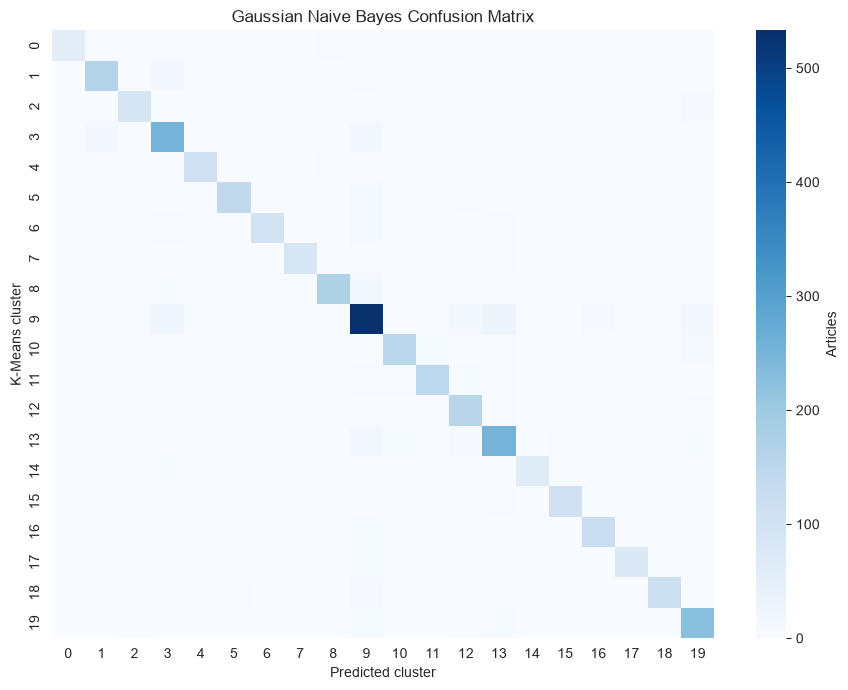

In [20]:
from sklearn.naive_bayes import GaussianNB

# Train Gaussian Naive Bayes using the reduced SVD/LSA features
nb = GaussianNB()
nb.fit(X_train, train_clusters)

# Predict clusters for unseen test articles
nb_pred = nb.predict(X_test)

print("Gaussian Naive Bayes accuracy on test articles:",
      round(accuracy_score(test_clusters, nb_pred), 4))
print()
print(classification_report(test_clusters, nb_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(test_clusters, nb_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, cmap="Blues", cbar_kws={"label": "Articles"})
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.xlabel("Predicted cluster")
plt.ylabel("K-Means cluster")
plt.tight_layout()
plt.show()

### Inspect Naive Bayes errors

In [21]:
errors = test_df.assign(kmeans_cluster=test_clusters, nb_prediction=nb_pred)
errors = errors[errors["kmeans_cluster"] != errors["nb_prediction"]]
print("Misclassified test articles:", len(errors), "of", len(test_df))

for _, row in errors.head(4).iterrows():
    print("=" * 70)
    print(f"K-Means cluster: {row['kmeans_cluster']}   Naive Bayes predicted: {row['nb_prediction']}")
    print(row["article"].strip()[:300].replace("\n", " "))

Misclassified test articles: 408 of 3541
K-Means cluster: 9   Naive Bayes predicted: 19
That is in fact the current version (it only came out in December).   My test movie was created at 320*240 resolution, it wasn't being scaled up. Scaling was a very CPU-intensive operation with the original QuickTime (1.0); the current version has optimizations for ratios like 4:1 (160*120 -> 320*24
K-Means cluster: 9   Naive Bayes predicted: 16
: I was posting to Alt.locksmithing about the best methods for securing  : a motorcycle.  I got several responses referring to the Cobra Lock : (described below).  Has anyone come across a store carrying this lock : in the Chicago area? :  : Any other feedback from someone who has used this?  What a
K-Means cluster: 8   Naive Bayes predicted: 3
: The Swiss population is (and well was) far larger than that. I think : your question should be, "...losing sleep over a million expert : riflemen?" Certainly he could have conquered Switzerland, but : a million arme

Errors usually happen on short articles or on topics that share vocabulary (for example the two religion clusters, or hardware vs. software).

## Step 14: Final summary

In [22]:
print("=" * 55)
print("NEWS TOPIC DISCOVERY: FINAL RESULTS")
print("=" * 55)
print("Articles used (after cleaning):", len(df))
print("Training / testing articles   :", len(train_df), "/", len(test_df))
print("TF-IDF features               :", X_train_tfidf.shape[1])
print("SVD dimensions                :", BEST_DIMS)
print("Clusters (k)                  :", BEST_K)
print()
print(final.to_string())
print()
print("Naive Bayes accuracy on test clusters:", round(accuracy_score(test_clusters, nb_pred), 4))

NEWS TOPIC DISCOVERY: FINAL RESULTS
Articles used (after cleaning): 17705
Training / testing articles   : 14164 / 3541
TF-IDF features               : 20000
SVD dimensions                : 100
Clusters (k)                  : 20

            Version 1 (baseline, test)  (train)  (test)
Silhouette                      0.0469   0.0579  0.0569
ARI                             0.0657   0.2349  0.2263
NMI                                NaN   0.4625  0.4555

Naive Bayes accuracy on test clusters: 0.8848


In [19]:
# 1. Map each cluster ID to its most common/dominant category
cluster_to_topic = dominant.to_dict()

# 2. Function to predict the topic of any new article text
def predict_topic(text):
    # Clean the input text using the cleaning function from Step 3
    cleaned = clean_text(text)
    
    # Transform text using the trained TF-IDF vectorizer
    tfidf_vec = tfidf.transform([cleaned])
    
    # Reduce dimensions using trained SVD and keep the best dimensions (100)
    svd_vec = svd.transform(tfidf_vec)[:, :BEST_DIMS]
    
    # Normalize length to 1 (same as training)
    norm_vec = normalize(svd_vec)
    
    # Predict the nearest cluster using the trained KMeans model
    pred_cluster = kmeans.predict(norm_vec)[0]
    
    # Get the assigned topic label and the top keywords for this cluster
    assigned_topic = cluster_to_topic[pred_cluster]
    keywords = cluster_table.loc[pred_cluster, "Top words"]
    
    return pred_cluster, assigned_topic, keywords

# 3. Take input from the user and display the result
user_article = input("Enter or paste your article text here:\n")

if user_article.strip():
    cluster_id, topic_name, topic_keywords = predict_topic(user_article)
    
    print("\n" + "=" * 45)
    print(f"Predicted Cluster : {cluster_id}")
    print(f"Likely Category   : {topic_name}")
    print(f"Topic Keywords    : {topic_keywords}")
    print("=" * 45)
else:
    print("No text was entered.")

No text was entered.
